In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor

In [4]:
df = pd.read_csv(
    "../data/processed/clean_sales.csv"
)

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (9994, 27)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688  2016-06-12         NaN    Second Class    DV-13045   
3       4  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   
4       5  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...     Sales  \
0      Claire Gute   Consumer  United States        Henderson  ...  261.9600   
1      Claire Gute   Consumer  United States        Henderson  ...  731.9400   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   14.6200   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...  957.5775   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   22.3680   

   Qua

In [5]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"]
)

print("Start Date:", df["Order Date"].min())
print("End Date:", df["Order Date"].max())

Start Date: 2014-01-03 00:00:00
End Date: 2017-12-11 00:00:00


Aggregate sales by month

In [7]:
monthly_sales = (
    df.set_index("Order Date")
      .resample("MS")["Sales"]
      .sum()
      .reset_index()
)

print(monthly_sales.head())

  Order Date      Sales
0 2014-01-01   4923.616
1 2014-02-01   3610.402
2 2014-03-01   8048.773
3 2014-04-01  16040.811
4 2014-05-01   9288.864


In [8]:
monthly_sales.columns = [
    "Month",
    "Sales"
]

print(monthly_sales)

        Month       Sales
0  2014-01-01   4923.6160
1  2014-02-01   3610.4020
2  2014-03-01   8048.7730
3  2014-04-01  16040.8110
4  2014-05-01   9288.8640
5  2014-06-01  17235.9460
6  2014-07-01   8827.5750
7  2014-08-01  16852.6840
8  2014-09-01  32826.0590
9  2014-10-01   7004.0870
10 2014-11-01  32603.2822
11 2014-12-01  21644.5905
12 2015-01-01   6528.3756
13 2015-02-01   4241.3740
14 2015-03-01  10057.0474
15 2015-04-01   8101.9360
16 2015-05-01   9681.4540
17 2015-06-01   9047.7420
18 2015-07-01  10741.6690
19 2015-08-01  10603.9792
20 2015-09-01  14351.4900
21 2015-10-01  12066.0725
22 2015-11-01  37379.2940
23 2015-12-01  31413.0510
24 2016-01-01   6836.8480
25 2016-02-01  17039.1400
26 2016-03-01  28157.2050
27 2016-04-01  15854.1550
28 2016-05-01  14800.8650
29 2016-06-01  16969.9960
30 2016-07-01  13059.8470
31 2016-08-01   8931.7085
32 2016-09-01  41214.5446
33 2016-10-01  30056.2490
34 2016-11-01  33052.1888
35 2016-12-01  45517.1060
36 2017-01-01  11076.9750
37 2017-02-0

In [9]:
print(
    "Number of months:",
    len(monthly_sales)
)

Number of months: 48


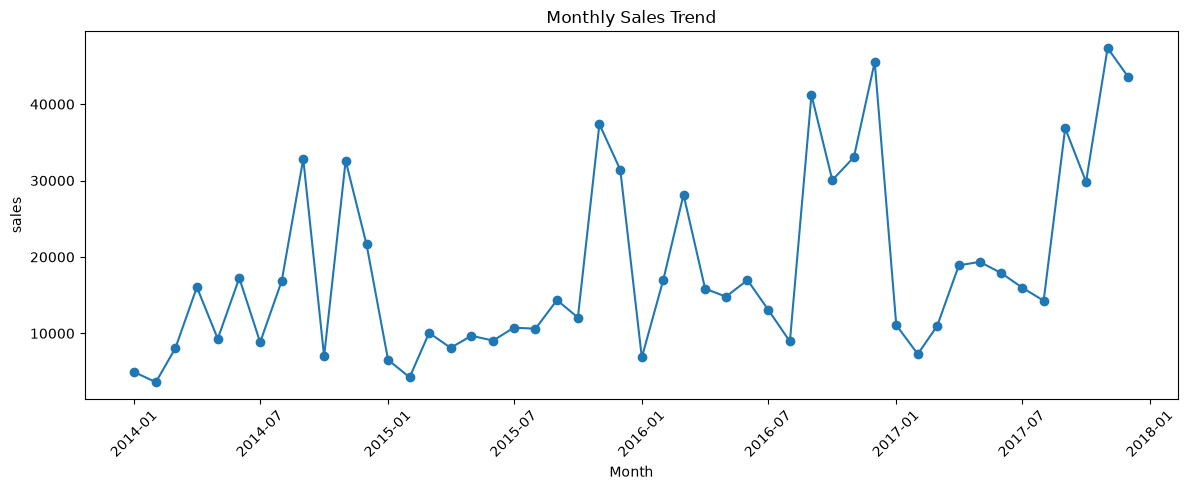

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("sales")
plt.title("Monthly Sales Trend")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
monthly_sales["Year"] = (
    monthly_sales["Month"].dt.year
)

monthly_sales["Month_Number"] = (
    monthly_sales["Month"].dt.month
)

monthly_sales["Quarter"] = (
    monthly_sales["Month"].dt.quarter
)

In [12]:
monthly_sales["Time_Index"] = np.arange(
    len(monthly_sales)
)
print(monthly_sales.head())

       Month      Sales  Year  Month_Number  Quarter  Time_Index
0 2014-01-01   4923.616  2014             1        1           0
1 2014-02-01   3610.402  2014             2        1           1
2 2014-03-01   8048.773  2014             3        1           2
3 2014-04-01  16040.811  2014             4        2           3
4 2014-05-01   9288.864  2014             5        2           4


In [13]:
monthly_sales["Lag_1"] = (
    monthly_sales["Sales"].shift(1)
)

In [14]:
monthly_sales["Lag_2"] = (
    monthly_sales["Sales"].shift(2)
)

In [15]:
monthly_sales["Lag_3"] = (
    monthly_sales["Sales"].shift(3)
)

In [16]:
monthly_sales["Lag_6"] = (
    monthly_sales["Sales"].shift(6)
)

In [17]:
monthly_sales["Lag_12"] = (
    monthly_sales["Sales"].shift(12)
)

In [18]:
monthly_sales["Rolling_3"] = (
    monthly_sales["Sales"]
    .shift(1)
    .rolling(3)
    .mean()
)

In [19]:
monthly_sales["Rolling_6"] = (
    monthly_sales["Sales"]
    .shift(1)
    .rolling(6)
    .mean()
)

In [20]:
print(
    monthly_sales.head(15)
)

        Month       Sales  Year  Month_Number  Quarter  Time_Index  \
0  2014-01-01   4923.6160  2014             1        1           0   
1  2014-02-01   3610.4020  2014             2        1           1   
2  2014-03-01   8048.7730  2014             3        1           2   
3  2014-04-01  16040.8110  2014             4        2           3   
4  2014-05-01   9288.8640  2014             5        2           4   
5  2014-06-01  17235.9460  2014             6        2           5   
6  2014-07-01   8827.5750  2014             7        3           6   
7  2014-08-01  16852.6840  2014             8        3           7   
8  2014-09-01  32826.0590  2014             9        3           8   
9  2014-10-01   7004.0870  2014            10        4           9   
10 2014-11-01  32603.2822  2014            11        4          10   
11 2014-12-01  21644.5905  2014            12        4          11   
12 2015-01-01   6528.3756  2015             1        1          12   
13 2015-02-01   4241

In [21]:
forecast_df = monthly_sales.dropna().copy()

In [22]:
print(
    "Original rows:",
    len(monthly_sales)
)

print(
    "Forecast rows:",
    len(forecast_df)
)

Original rows: 48
Forecast rows: 36


In [23]:
split_index = int(
    len(forecast_df) * 0.80
)

train = forecast_df.iloc[
    :split_index
].copy()

test = forecast_df.iloc[
    split_index:
].copy()

In [24]:
print("Training rows:", len(train))
print("Testing rows:", len(test))

print(
    "\nTraining period:",
    train["Month"].min(),
    "to",
    train["Month"].max()
)

print(
    "Testing period:",
    test["Month"].min(),
    "to",
    test["Month"].max()
)

Training rows: 28
Testing rows: 8

Training period: 2015-01-01 00:00:00 to 2017-04-01 00:00:00
Testing period: 2017-05-01 00:00:00 to 2017-12-01 00:00:00


In [25]:
features = [
    "Year",
    "Month_Number",
    "Quarter",
    "Time_Index",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_6",
    "Lag_12",
    "Rolling_3",
    "Rolling_6"
]

target = "Sales"

In [26]:
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

In [27]:
baseline_predictions = test["Lag_1"]

In [28]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

In [29]:
print("Baseline Forecast")
print("=" * 40)

print(
    f"MAE  : {baseline_mae:.2f}"
)

print(
    f"RMSE : {baseline_rmse:.2f}"
)

Baseline Forecast
MAE  : 7061.61
RMSE : 10544.58


Train Random Forest

In [30]:
rf_forecast = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [31]:
rf_forecast.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [32]:
rf_predictions = rf_forecast.predict(
    X_test
)

In [33]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

In [34]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

In [35]:
print("Random Forest Forecast")
print("=" * 40)

print(f"MAE  : {rf_mae:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"R²   : {rf_r2:.4f}")

Random Forest Forecast
MAE  : 4044.48
RMSE : 5425.53
R²   : 0.8048


Compare baseline vs ML

In [37]:
forecast_results = pd.DataFrame({
    "Model": [
        "Previous Month Baseline",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse
    ]
})

print(
    forecast_results.round(2)
)

                     Model      MAE      RMSE
0  Previous Month Baseline  7061.61  10544.58
1            Random Forest  4044.48   5425.53


actual vs predicted dataset

In [39]:
comparison = test[
    ["Month", "Sales"]
].copy()

comparison["Forecast"] = rf_predictions

print(comparison)

        Month       Sales      Forecast
40 2017-05-01  19357.8208  16262.189090
41 2017-06-01  17888.3560  15273.160792
42 2017-07-01  15992.8080  15615.007454
43 2017-08-01  14269.2740  14202.049451
44 2017-09-01  36850.9140  27771.469432
45 2017-10-01  29834.0830  32508.071829
46 2017-11-01  47347.7850  36590.120776
47 2017-12-01  43517.1250  39828.210908


Plot actual vs forecast

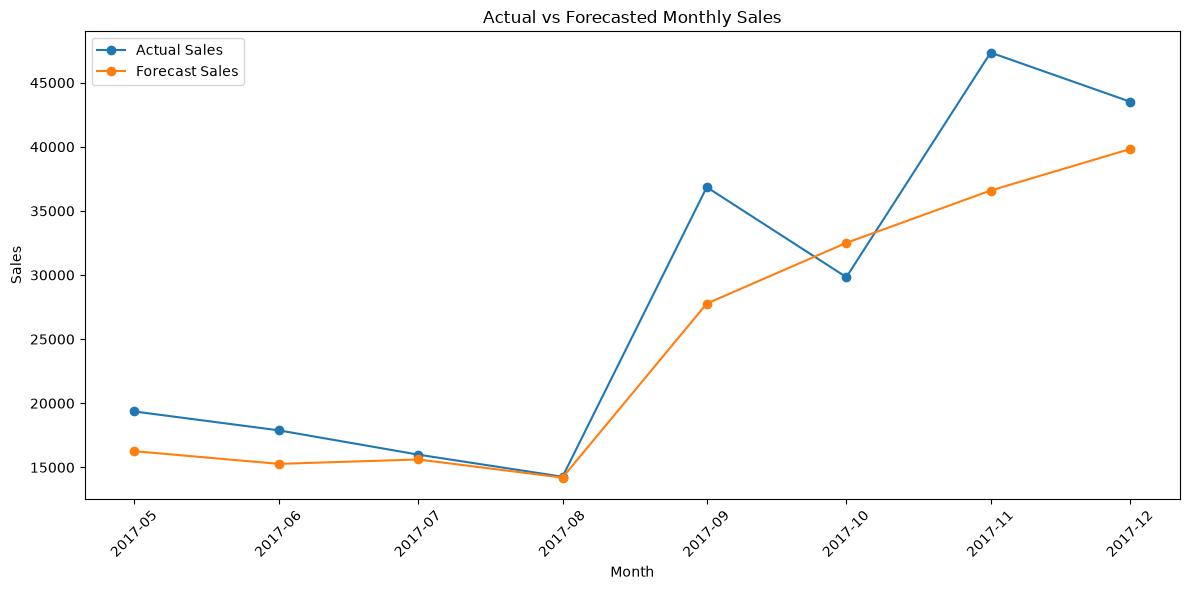

In [40]:
plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Month"],
    comparison["Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    comparison["Month"],
    comparison["Forecast"],
    marker="o",
    label="Forecast Sales"
)

plt.xlabel("Month")
plt.ylabel("Sales")

plt.title(
    "Actual vs Forecasted Monthly Sales"
)

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Calculate forecast error

In [43]:
comparison["Error"] = (
    comparison["Sales"]
    - comparison["Forecast"]
)

comparison["Percentage_Error"] = (
    comparison["Error"]
    / comparison["Sales"]
) * 100

print(comparison)

        Month       Sales      Forecast         Error  Percentage_Error
40 2017-05-01  19357.8208  16262.189090   3095.631710         15.991633
41 2017-06-01  17888.3560  15273.160792   2615.195208         14.619539
42 2017-07-01  15992.8080  15615.007454    377.800546          2.362315
43 2017-08-01  14269.2740  14202.049451     67.224549          0.471114
44 2017-09-01  36850.9140  27771.469432   9079.444568         24.638316
45 2017-10-01  29834.0830  32508.071829  -2673.988829         -8.962866
46 2017-11-01  47347.7850  36590.120776  10757.664224         22.720523
47 2017-12-01  43517.1250  39828.210908   3688.914092          8.476925


In [44]:
importance = rf_forecast.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

         Feature  Importance
1   Month_Number    0.574600
3     Time_Index    0.088145
5          Lag_2    0.064900
2        Quarter    0.049471
10     Rolling_6    0.046016
4          Lag_1    0.042267
8         Lag_12    0.037486
9      Rolling_3    0.034391
6          Lag_3    0.028248
7          Lag_6    0.028030
0           Year    0.006445


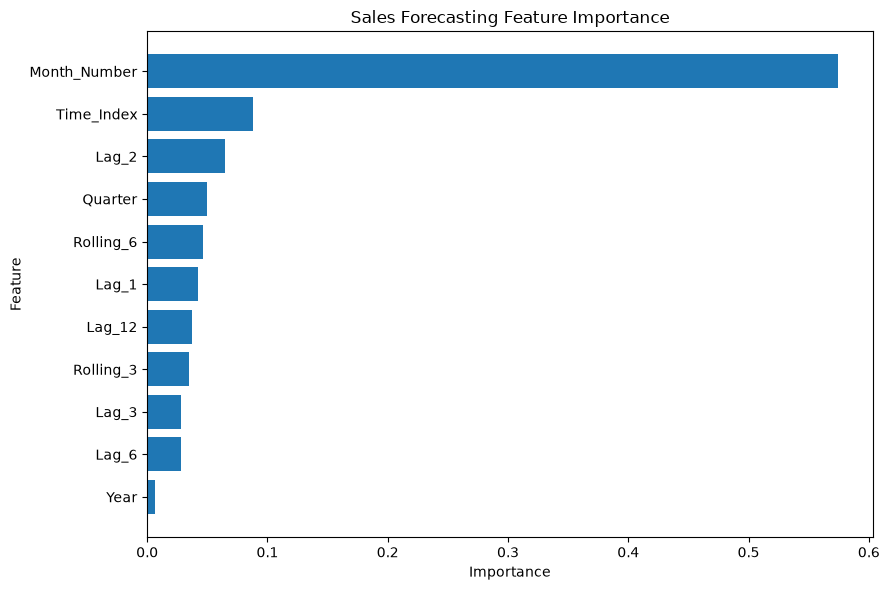

In [45]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Sales Forecasting Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

Create future forecasting function

In [46]:
def forecast_future(
    model,
    historical_data,
    periods=6
):
    
    history = historical_data[
        ["Month", "Sales"]
    ].copy()

    predictions = []

    for _ in range(periods):

        next_month = (
            history["Month"].max()
            + pd.DateOffset(months=1)
        )

        temp = history.copy()

        row = {
            "Month": next_month
        }

        row["Year"] = next_month.year
        row["Month_Number"] = next_month.month
        row["Quarter"] = next_month.quarter
        row["Time_Index"] = len(history)

        row["Lag_1"] = history["Sales"].iloc[-1]

        row["Lag_2"] = (
            history["Sales"].iloc[-2]
        )

        row["Lag_3"] = (
            history["Sales"].iloc[-3]
        )

        row["Lag_6"] = (
            history["Sales"].iloc[-6]
        )

        row["Lag_12"] = (
            history["Sales"].iloc[-12]
        )

        row["Rolling_3"] = (
            history["Sales"]
            .iloc[-3:]
            .mean()
        )

        row["Rolling_6"] = (
            history["Sales"]
            .iloc[-6:]
            .mean()
        )

        feature_row = pd.DataFrame(
            [row]
        )[features]

        prediction = model.predict(
            feature_row
        )[0]

        predictions.append({
            "Month": next_month,
            "Forecast_Sales": prediction
        })

        new_row = pd.DataFrame({
            "Month": [next_month],
            "Sales": [prediction]
        })

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    return pd.DataFrame(predictions)

In [47]:
future_forecast = forecast_future(
    rf_forecast,
    monthly_sales,
    periods=6
)

print(future_forecast)

       Month  Forecast_Sales
0 2018-01-01    13350.210718
1 2018-02-01    12058.501147
2 2018-03-01    12829.903045
3 2018-04-01    13594.923222
4 2018-05-01    14547.398723
5 2018-06-01    14749.226600


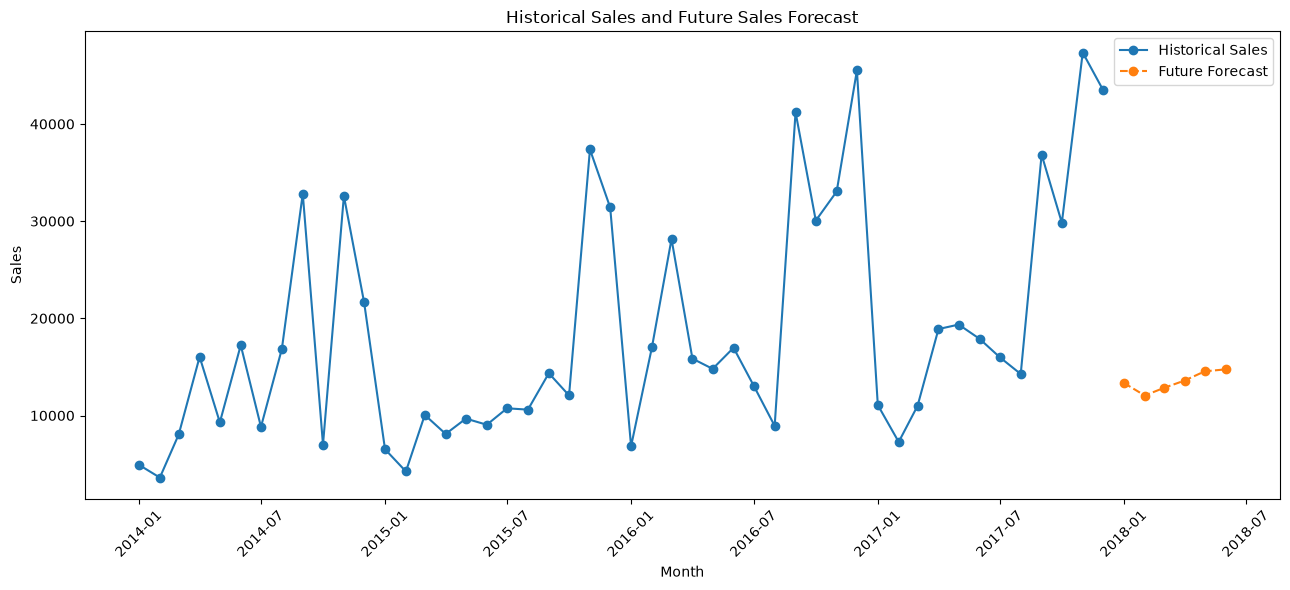

In [48]:
plt.figure(figsize=(13, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o",
    label="Historical Sales"
)

plt.plot(
    future_forecast["Month"],
    future_forecast["Forecast_Sales"],
    marker="o",
    linestyle="--",
    label="Future Forecast"
)

plt.xlabel("Month")
plt.ylabel("Sales")

plt.title(
    "Historical Sales and Future Sales Forecast"
)

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [49]:
import os

os.makedirs(
    "../data/ml",
    exist_ok = True
)

future_forecast.to_csv(
    "../data/ml/sales_forecast.csv",
    index=False
)

In [52]:
os.makedirs(
    "../models",
    exist_ok=True
)

joblib.dump(
    rf_forecast,
    "../models/sales_forecasting_model.pkl"
)

['../models/sales_forecasting_model.pkl']

In [53]:
monthly_sales.to_csv(
    "../data/ml/monthly_sales.csv",
    index=False
)